In [1]:
!pip install -q git+https://github.com/openai/CLIP.git

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.5 MB/s eta 0:00:00


In [2]:
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)
import matplotlib.pyplot as plt
import clip
from tqdm import tqdm

In [3]:
# ============================================================
# CONFIG
# ============================================================
class CFG:
    DATASET_ROOT   = "/kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2"

    # sequence
    MAX_STEPS      = 16          # max frames per video (2 s sampling interval)
    MEL_SLICE_W    = 32          # width (time px) of each per-step mel slice
    MEL_H          = 128         # mel image height after resize (freq axis)

    # model dims
    CLIP_DIM       = 512         # ViT-B/32
    AUDIO_DIM      = 256
    PROJ_DIM       = 128         # shared coherence space
    STATE_DIM      = 256
    GRU_HIDDEN     = 256

    # TD formulation
    GAMMA          = 0.95        # discount
    LAMBDA         = 0.8         # TD(λ) trace parameter
    ETA            = 0.10        # shaped-reward weight  (ETA = 0.0 → terminal-only ablation)
    TERMINAL_SCALE = 1.0         # |terminal reward|
    W_CLS          = 1.0         # weight of terminal BCE vs TD loss

    # training
    BATCH_SIZE     = 8
    EPOCHS_STAGE1  = 8           # coherence pretraining
    EPOCHS_STAGE2  = 20          # value training
    LR_STAGE1      = 1e-3
    LR_STAGE2      = 1e-3
    TEMPERATURE    = 0.07        # InfoNCE
    NUM_WORKERS    = 4
    SEED           = 42

def set_seed(seed=CFG.SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
# ============================================================
# DATASET — frames + PER-STEP mel slices (temporally aligned)
# ============================================================
class TDPolyGlotFakeDataset(Dataset):
    """
    Returns per sample:
        frames     : (MAX_STEPS, 3, 224, 224)  zero-padded
        mel_slices : (MAX_STEPS, 3, MEL_H, MEL_SLICE_W)  zero-padded
        mask       : (MAX_STEPS,)  1 for valid steps
        label      : ()  0 = Real, 1 = Fake

    The full-video mel spectrogram image is resized to width F * MEL_SLICE_W
    (F = number of valid frames) and cut into F equal time windows, so
    step t pairs frame_t with the audio spanning the same portion of the video.
    """
    def __init__(self, data_list, clip_preprocess):
        self.data_list = data_list
        self.clip_preprocess = clip_preprocess

    def __len__(self):
        return len(self.data_list)

    def _load_frames(self, frames_folder):
        files = sorted(f for f in os.listdir(frames_folder) if f.endswith('.png'))
        files = files[:CFG.MAX_STEPS]
        frames = []
        for fn in files:
            try:
                img = Image.open(os.path.join(frames_folder, fn)).convert('RGB')
                frames.append(self.clip_preprocess(img))
            except Exception as e:
                print(f"Frame load error {fn}: {e}")
        if not frames:
            frames = [torch.zeros(3, 224, 224)]
        return torch.stack(frames)                      # (F, 3, 224, 224)

    def _load_mel_slices(self, mel_path, num_steps):
        try:
            mel = Image.open(mel_path).convert('RGB')
        except Exception as e:
            print(f"Mel load error {mel_path}: {e}")
            return torch.zeros(num_steps, 3, CFG.MEL_H, CFG.MEL_SLICE_W)
        mel = TF.to_tensor(TF.resize(mel, (CFG.MEL_H, num_steps * CFG.MEL_SLICE_W)))
        # (3, H, F*W) -> F slices of (3, H, W)
        slices = mel.unfold(dimension=2, size=CFG.MEL_SLICE_W, step=CFG.MEL_SLICE_W)
        return slices.permute(2, 0, 1, 3).contiguous()  # (F, 3, H, W)

    def __getitem__(self, idx):
        frames_folder, mel_path, label = self.data_list[idx]
        frames = self._load_frames(frames_folder)       # (F, ...)
        F_valid = frames.size(0)
        mel_slices = self._load_mel_slices(mel_path, F_valid)

        T = CFG.MAX_STEPS
        pad_f = torch.zeros(T, 3, 224, 224)
        pad_a = torch.zeros(T, 3, CFG.MEL_H, CFG.MEL_SLICE_W)
        pad_f[:F_valid] = frames
        pad_a[:F_valid] = mel_slices
        mask = torch.zeros(T)
        mask[:F_valid] = 1.0

        return pad_f, pad_a, mask, torch.tensor(label, dtype=torch.long)


def collate_fn(batch):
    frames, mels, masks, labels = zip(*batch)
    return (torch.stack(frames), torch.stack(mels),
            torch.stack(masks), torch.stack(labels))

In [5]:
# ============================================================
# DATA SPLITS — same directory walk as the previous pipeline
# ============================================================
def prepare_data_splits(dataset_root, train_ratio=0.7, val_ratio=0.1, test_ratio=0.2):
    def collect(class_dir, label):
        out = []
        root = os.path.join(dataset_root, class_dir)
        if not os.path.exists(root):
            return out
        for vid in os.listdir(root):
            vp = os.path.join(root, vid)
            if not os.path.isdir(vp):
                continue
            audio_p, frames_p = os.path.join(vp, 'Audio'), os.path.join(vp, 'Frames')
            if os.path.exists(audio_p) and os.path.exists(frames_p):
                mels = [f for f in os.listdir(audio_p)
                        if 'spectrogram' in f.lower() and f.endswith('.png')]
                if mels:
                    out.append((frames_p, os.path.join(audio_p, mels[0]), label))
        return out

    real_data, fake_data = collect('Real', 0), collect('Fake', 1)
    print(f"Found {len(real_data)} real / {len(fake_data)} fake samples")

    def split(data):
        tr, tmp = train_test_split(data, test_size=(1 - train_ratio), random_state=CFG.SEED)
        va, te  = train_test_split(tmp, test_size=test_ratio / (test_ratio + val_ratio),
                                   random_state=CFG.SEED)
        return tr, va, te

    r_tr, r_va, r_te = split(real_data)
    f_tr, f_va, f_te = split(fake_data)
    train, val, test = r_tr + f_tr, r_va + f_va, r_te + f_te
    for s in (train, val, test):
        random.shuffle(s)
    print(f"Train {len(train)} | Val {len(val)} | Test {len(test)}")
    return train, val, test

In [6]:
# ============================================================
# ENCODERS
# ============================================================
class AudioSliceEncoder(nn.Module):
    """Per-step mel slice (3, MEL_H, MEL_SLICE_W) -> AUDIO_DIM vector."""
    def __init__(self, out_dim=CFG.AUDIO_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 1)),
        )
        self.fc = nn.Linear(128 * 4, out_dim)

    def forward(self, x):
        # x: (N, 3, H, W)
        h = self.conv(x).flatten(1)
        return self.fc(h)


class FrameEncoder(nn.Module):
    """Frozen CLIP ViT-B/32 image encoder over the step axis."""
    def __init__(self, clip_model):
        super().__init__()
        self.clip_model = clip_model
        for p in self.clip_model.parameters():
            p.requires_grad = False

    @torch.no_grad()
    def forward(self, frames):
        # frames: (B, T, 3, 224, 224) -> (B, T, CLIP_DIM)
        B, T = frames.shape[:2]
        flat = frames.reshape(B * T, *frames.shape[2:])
        feats = self.clip_model.encode_image(flat).float()
        return feats.view(B, T, -1)

In [7]:
# ============================================================
# STAGE-1 OBJECTIVE — audio-visual coherence (trained on REAL only)
# ============================================================
class CoherenceHead(nn.Module):
    """
    Projects frame and audio-slice embeddings into a shared PROJ_DIM sphere.
    c_t = cosine(z_v(t), z_a(t))  ∈ [-1, 1]  — per-step AV coherence.
    """
    def __init__(self):
        super().__init__()
        self.proj_v = nn.Sequential(
            nn.Linear(CFG.CLIP_DIM, CFG.PROJ_DIM * 2), nn.GELU(),
            nn.Linear(CFG.PROJ_DIM * 2, CFG.PROJ_DIM))
        self.proj_a = nn.Sequential(
            nn.Linear(CFG.AUDIO_DIM, CFG.PROJ_DIM * 2), nn.GELU(),
            nn.Linear(CFG.PROJ_DIM * 2, CFG.PROJ_DIM))

    def forward(self, v_feats, a_feats):
        # (B, T, D) each -> z_v, z_a: (B, T, PROJ_DIM), coherence: (B, T)
        z_v = F.normalize(self.proj_v(v_feats), dim=-1)
        z_a = F.normalize(self.proj_a(a_feats), dim=-1)
        c = (z_v * z_a).sum(-1)
        return z_v, z_a, c


def info_nce_real_only(z_v, z_a, mask, labels, temperature=CFG.TEMPERATURE):
    """
    Symmetric InfoNCE over all valid steps of REAL videos in the batch.
    Positives:  (z_v[i, t], z_a[i, t]) — same video, same step.
    Negatives:  every other (video, step) audio/visual in the batch —
                includes same-video-different-step pairs, i.e. temporal
                misalignment negatives come for free.
    """
    real = (labels == 0)
    if real.sum() == 0:
        return torch.tensor(0.0, device=z_v.device, requires_grad=True)
    m = (mask.bool() & real.unsqueeze(1))          # (B, T)
    zv, za = z_v[m], z_a[m]                        # (N, PROJ_DIM)
    if zv.size(0) < 2:
        return torch.tensor(0.0, device=z_v.device, requires_grad=True)
    logits = zv @ za.t() / temperature             # (N, N)
    target = torch.arange(zv.size(0), device=zv.device)
    return 0.5 * (F.cross_entropy(logits, target) +
                  F.cross_entropy(logits.t(), target))

In [8]:
# ============================================================
# STAGE-2 OBJECTIVE — TD(λ) value network over fused states
# ============================================================
class ValueNetwork(nn.Module):
    """
    State s_t = [clip_t ; audio_t ; c_t]  ->  fusion MLP  ->  causal GRU  ->  V(s_t).
    A 2-parameter calibration maps the terminal value to P(fake).
    Convention: V > 0 → evidence of FAKE, V < 0 → evidence of REAL.
    """
    def __init__(self):
        super().__init__()
        in_dim = CFG.CLIP_DIM + CFG.AUDIO_DIM + 1
        self.fusion = nn.Sequential(
            nn.Linear(in_dim, CFG.STATE_DIM), nn.LayerNorm(CFG.STATE_DIM),
            nn.ReLU(), nn.Dropout(0.3))
        self.gru = nn.GRU(CFG.STATE_DIM, CFG.GRU_HIDDEN, batch_first=True)  # causal
        self.value_head = nn.Sequential(
            nn.Linear(CFG.GRU_HIDDEN, 64), nn.ReLU(), nn.Linear(64, 1))
        self.calib_a = nn.Parameter(torch.tensor(1.0))
        self.calib_b = nn.Parameter(torch.tensor(0.0))

    def forward(self, v_feats, a_feats, coherence):
        s = torch.cat([v_feats, a_feats, coherence.unsqueeze(-1)], dim=-1)
        h, _ = self.gru(self.fusion(s))            # (B, T, H) — causal in t
        V = self.value_head(h).squeeze(-1)         # (B, T)
        return V

    def prob_fake(self, V_t):
        return torch.sigmoid(self.calib_a * V_t + self.calib_b)


def shaped_rewards(coherence, mask, labels):
    """
    r_t = ETA * (1 - c_t)          desync accumulates fakeness evidence
    r_{T_i} += ±TERMINAL_SCALE     terminal grounding (+1 fake / -1 real)
    """
    B, T = coherence.shape
    r = CFG.ETA * (1.0 - coherence) * mask
    lengths = mask.sum(1).long().clamp(min=1)
    terminal = torch.where(labels == 1,
                           torch.full_like(labels, 1, dtype=torch.float),
                           torch.full_like(labels, -1, dtype=torch.float))
    r[torch.arange(B, device=r.device), lengths - 1] += CFG.TERMINAL_SCALE * terminal
    return r


def td_lambda_returns(rewards, values, mask, gamma=CFG.GAMMA, lam=CFG.LAMBDA):
    """
    Offline λ-returns (episodes fully observed), backward recursion:
        G_t = r_t + γ [ (1-λ) V(s_{t+1}) + λ G_{t+1} ]      (t < T_i)
        G_{T_i} = r_{T_i}                                   (no bootstrap past episode)
    values must be detached (semi-gradient TD).
    """
    B, T = rewards.shape
    lengths = mask.sum(1).long().clamp(min=1)
    G = torch.zeros_like(rewards)
    next_G = torch.zeros(B, device=rewards.device)
    for t in reversed(range(T)):
        valid = mask[:, t].bool()
        is_last = (lengths - 1) == t
        v_next = values[:, t + 1] if t + 1 < T else torch.zeros(B, device=rewards.device)
        bootstrap = (1 - lam) * v_next + lam * next_G
        G_t = rewards[:, t] + gamma * torch.where(is_last, torch.zeros_like(bootstrap), bootstrap)
        G[:, t] = torch.where(valid, G_t, torch.zeros_like(G_t))
        next_G = torch.where(valid, G_t, next_G)
    return G

In [9]:
# ============================================================
# FULL MODEL
# ============================================================
class TDVerdict(nn.Module):
    def __init__(self, clip_model):
        super().__init__()
        self.frame_enc = FrameEncoder(clip_model)
        self.audio_enc = AudioSliceEncoder()
        self.coherence = CoherenceHead()
        self.value_net = ValueNetwork()

    def encode(self, frames, mel_slices):
        B, T = mel_slices.shape[:2]
        v = self.frame_enc(frames)                                    # (B, T, 512) frozen
        a = self.audio_enc(mel_slices.reshape(B * T, *mel_slices.shape[2:]))
        return v, a.view(B, T, -1)

    def forward(self, frames, mel_slices, freeze_coherence=False):
        if freeze_coherence:
            # Stage 2: audio encoder + coherence head are frozen — the reward
            # signal c_t cannot be gamed by the value objective (no reward hacking).
            with torch.no_grad():
                v, a = self.encode(frames, mel_slices)
                z_v, z_a, c = self.coherence(v, a)
        else:
            v, a = self.encode(frames, mel_slices)
            z_v, z_a, c = self.coherence(v, a)
        V = self.value_net(v, a, c)
        return {"V": V, "coherence": c, "z_v": z_v, "z_a": z_a}

    def stage1_parameters(self):
        return list(self.audio_enc.parameters()) + list(self.coherence.parameters())

    def stage2_parameters(self):
        return list(self.value_net.parameters())

    def freeze_stage1(self):
        for p in self.stage1_parameters():
            p.requires_grad = False
        self.audio_enc.eval()
        self.coherence.eval()

In [10]:
# ============================================================
# STAGE 1 — coherence pretraining (InfoNCE, real videos only)
# ============================================================
def train_stage1(model, train_loader, val_loader, epochs=CFG.EPOCHS_STAGE1):
    opt = optim.Adam(model.stage1_parameters(), lr=CFG.LR_STAGE1)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    history = []

    for epoch in range(epochs):
        model.train()
        total, steps = 0.0, 0
        pbar = tqdm(train_loader, desc=f"Stage1 [{epoch+1}/{epochs}]")
        for frames, mels, mask, labels in pbar:
            frames, mels = frames.to(device), mels.to(device)
            mask, labels = mask.to(device), labels.to(device)
            if (labels == 0).sum() == 0:
                continue
            out = model(frames, mels, freeze_coherence=False)
            loss = info_nce_real_only(out["z_v"], out["z_a"], mask, labels)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.stage1_parameters(), 1.0)
            opt.step()
            total += loss.item(); steps += 1
            pbar.set_postfix({"nce": f"{loss.item():.4f}"})
        sched.step()

        # sanity metric: mean coherence on real vs fake validation videos —
        # a growing gap means the coherence signal is informative
        model.eval()
        c_real, c_fake = [], []
        with torch.no_grad():
            for frames, mels, mask, labels in val_loader:
                frames, mels = frames.to(device), mels.to(device)
                mask, labels = mask.to(device), labels.to(device)
                out = model(frames, mels)
                c = out["coherence"]
                for i in range(len(labels)):
                    m = mask[i].bool()
                    (c_real if labels[i] == 0 else c_fake).append(c[i][m].mean().item())
        gap = float(np.mean(c_real) - np.mean(c_fake)) if c_real and c_fake else 0.0
        print(f"  train NCE {total/max(steps,1):.4f} | val ⟨c⟩ real {np.mean(c_real):.4f} "
              f"fake {np.mean(c_fake):.4f} | gap {gap:+.4f}")
        history.append({"epoch": epoch + 1, "nce": total / max(steps, 1),
                        "c_real": float(np.mean(c_real)), "c_fake": float(np.mean(c_fake))})
    return history

In [11]:
# ============================================================
# STAGE 2 — TD(λ) value training with terminal BCE grounding
# ============================================================
def stage2_loss(model, out, mask, labels):
    """L = L_TD(λ)  +  W_CLS · L_BCE(terminal)  — the dual objective."""
    V, c = out["V"], out["coherence"]
    r = shaped_rewards(c, mask, labels.float())
    with torch.no_grad():
        G = td_lambda_returns(r, V.detach(), mask)     # semi-gradient targets
    td = (F.mse_loss(V, G, reduction="none") * mask).sum() / mask.sum()

    lengths = mask.sum(1).long().clamp(min=1)
    V_last = V[torch.arange(V.size(0), device=V.device), lengths - 1]
    p = torch.clamp(model.value_net.prob_fake(V_last), 1e-6, 1 - 1e-6)
    bce = F.binary_cross_entropy(p, labels.float())
    return td + CFG.W_CLS * bce, td.item(), bce.item()


def train_stage2(model, train_loader, val_loader, epochs=CFG.EPOCHS_STAGE2):
    model.freeze_stage1()
    opt = optim.Adam(model.stage2_parameters(), lr=CFG.LR_STAGE2)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)

    best_val_acc, best_epoch = 0.0, 0
    history = []
    for epoch in range(epochs):
        model.train()
        model.audio_enc.eval(); model.coherence.eval()   # keep frozen BN stats fixed
        tot, tot_td, tot_bce, steps = 0.0, 0.0, 0.0, 0
        preds, gts = [], []
        pbar = tqdm(train_loader, desc=f"Stage2 [{epoch+1}/{epochs}]")
        for frames, mels, mask, labels in pbar:
            frames, mels = frames.to(device), mels.to(device)
            mask, labels = mask.to(device), labels.to(device)
            out = model(frames, mels, freeze_coherence=True)
            loss, td_l, bce_l = stage2_loss(model, out, mask, labels)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.stage2_parameters(), 1.0)
            opt.step()

            tot += loss.item(); tot_td += td_l; tot_bce += bce_l; steps += 1
            lengths = mask.sum(1).long().clamp(min=1)
            V_last = out["V"][torch.arange(len(labels), device=device), lengths - 1]
            preds.extend((V_last > 0).long().cpu().numpy())
            gts.extend(labels.cpu().numpy())
            pbar.set_postfix({"loss": f"{loss.item():.4f}"})

        tr_acc = accuracy_score(gts, preds)
        val = evaluate(model, val_loader)
        sched.step(val["accuracy"])
        print(f"  train loss {tot/steps:.4f} (TD {tot_td/steps:.4f} BCE {tot_bce/steps:.4f}) "
              f"acc {tr_acc:.4f} | val acc {val['accuracy']:.4f} f1 {val['f1']:.4f} auc {val['auc']:.4f}")
        history.append({"epoch": epoch + 1, "train_acc": tr_acc, **{f"val_{k}": v
                        for k, v in val.items() if isinstance(v, float)}})

        if val["accuracy"] > best_val_acc:
            best_val_acc, best_epoch = val["accuracy"], epoch + 1
            torch.save({"model_state_dict": model.state_dict(),
                        "epoch": epoch, "val_acc": best_val_acc},
                       "best_tdverdict.pth")
            print(f"  ✓ saved (val acc {best_val_acc:.4f})")
    return history, best_epoch, best_val_acc

In [12]:
# ============================================================
# EVALUATION — standard metrics + collection of V trajectories
# ============================================================
@torch.no_grad()
def evaluate(model, loader, collect_trajectories=False):
    model.eval()
    probs, preds, gts = [], [], []
    trajs = []   # (V_traj, coherence_traj, length, label) if requested
    for frames, mels, mask, labels in loader:
        frames, mels = frames.to(device), mels.to(device)
        mask = mask.to(device)
        out = model(frames, mels, freeze_coherence=True)
        V = out["V"]
        lengths = mask.sum(1).long().clamp(min=1)
        V_last = V[torch.arange(len(labels), device=device), lengths - 1]
        p = model.value_net.prob_fake(V_last)
        probs.extend(p.cpu().numpy()); preds.extend((V_last > 0).long().cpu().numpy())
        gts.extend(labels.numpy())
        if collect_trajectories:
            for i in range(len(labels)):
                L = int(lengths[i])
                trajs.append((V[i, :L].cpu().numpy(),
                              out["coherence"][i, :L].cpu().numpy(),
                              L, int(labels[i])))
    gts, preds, probs = np.array(gts), np.array(preds), np.array(probs)
    res = {"accuracy": accuracy_score(gts, preds),
           "precision": precision_score(gts, preds, zero_division=0),
           "recall": recall_score(gts, preds, zero_division=0),
           "f1": f1_score(gts, preds, zero_division=0),
           "auc": roc_auc_score(gts, probs) if len(set(gts)) > 1 else 0.0,
           "preds": preds, "labels": gts, "probs": probs}
    if collect_trajectories:
        res["trajectories"] = trajs
    return res

In [13]:
# ============================================================
# EARLY-EXIT INFERENCE — accuracy vs. average steps consumed
# Exit at the first step where |V_t| > τ; verdict = sign(V_t).
# ============================================================
def early_exit_sweep(trajectories, thresholds=np.linspace(0.2, 2.0, 10)):
    rows = []
    for tau in thresholds:
        correct, steps_used = 0, 0
        for V, _, L, y in trajectories:
            exit_t = L - 1
            for t in range(L):
                if abs(V[t]) > tau:
                    exit_t = t
                    break
            pred = int(V[exit_t] > 0)
            correct += int(pred == y)
            steps_used += exit_t + 1
        n = len(trajectories)
        rows.append({"tau": float(tau), "accuracy": correct / n,
                     "avg_steps": steps_used / n,
                     "avg_video_pct": 100.0 * steps_used / sum(L for _, _, L, _ in trajectories)})
    return rows


def plot_early_exit(rows, full_acc):
    accs  = [r["accuracy"] for r in rows]
    steps = [r["avg_steps"] for r in rows]
    plt.figure(figsize=(6, 4))
    plt.plot(steps, accs, "o-", label="early exit")
    plt.axhline(full_acc, ls="--", c="gray", label=f"full video ({full_acc:.3f})")
    plt.xlabel("avg steps consumed (of ≤ 16)"); plt.ylabel("accuracy")
    plt.title("Early-exit: accuracy vs. computation"); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig("early_exit_curve.png", dpi=150); plt.show()

In [14]:
# ============================================================
# TEMPORAL LOCALIZATION — TD-error spikes mark manipulation evidence
# δ_t = r_t + γ V(s_{t+1}) − V(s_t)   (computed label-free: terminal
# reward unknown at inference, so δ uses only the shaped component)
# ============================================================
def td_errors_from_traj(V, c, gamma=CFG.GAMMA):
    r = CFG.ETA * (1.0 - c)
    delta = np.zeros(len(V))
    for t in range(len(V)):
        v_next = V[t + 1] if t + 1 < len(V) else 0.0
        delta[t] = r[t] + gamma * v_next - V[t]
    return delta


def plot_localization(trajectories, n_each=3):
    fakes = [t for t in trajectories if t[3] == 1][:n_each]
    reals = [t for t in trajectories if t[3] == 0][:n_each]
    fig, axes = plt.subplots(2, n_each, figsize=(4 * n_each, 6), squeeze=False)
    for j, (V, c, L, y) in enumerate(fakes):
        axes[0][j].plot(td_errors_from_traj(V, c), "r.-")
        axes[0][j].set_title(f"FAKE — TD error"); axes[0][j].grid(alpha=0.3)
    for j, (V, c, L, y) in enumerate(reals):
        axes[1][j].plot(td_errors_from_traj(V, c), "g.-")
        axes[1][j].set_title(f"REAL — TD error"); axes[1][j].grid(alpha=0.3)
    for ax in axes.flat:
        ax.set_xlabel("step (2 s each)")
    plt.tight_layout(); plt.savefig("td_error_localization.png", dpi=150); plt.show()

In [15]:
# ============================================================
# OPTIONAL — low-data adaptation of the value head only
# (k-shot per class; coherence/reward machinery stays frozen &
#  method-agnostic. For per-manipulation-method episodes, add
#  method metadata to data_list and group episodes by method.)
# ============================================================
def few_shot_adapt(model, train_data, test_loader, clip_preprocess,
                   k=5, adapt_epochs=10, lr=5e-4):
    set_seed(CFG.SEED)
    reals = [d for d in train_data if d[2] == 0][:k]
    fakes = [d for d in train_data if d[2] == 1][:k]
    ds = TDPolyGlotFakeDataset(reals + fakes, clip_preprocess)
    dl = DataLoader(ds, batch_size=min(2 * k, CFG.BATCH_SIZE), shuffle=True,
                    collate_fn=collate_fn)

    # fresh value head, frozen everything else
    model.value_net = ValueNetwork().to(device)
    model.freeze_stage1()
    opt = optim.Adam(model.stage2_parameters(), lr=lr)

    for _ in range(adapt_epochs):
        model.train(); model.audio_enc.eval(); model.coherence.eval()
        for frames, mels, mask, labels in dl:
            frames, mels = frames.to(device), mels.to(device)
            mask, labels = mask.to(device), labels.to(device)
            out = model(frames, mels, freeze_coherence=True)
            loss, _, _ = stage2_loss(model, out, mask, labels)
            opt.zero_grad(); loss.backward(); opt.step()

    res = evaluate(model, test_loader)
    print(f"[few-shot k={k}]  acc {res['accuracy']:.4f}  f1 {res['f1']:.4f}  auc {res['auc']:.4f}")
    return res

Loading CLIP...


100%|████████████████████████████████████████| 338M/338M [00:03<00:00, 106MiB/s]



Preparing splits...
Found 762 real / 13605 fake samples
Train 10056 | Val 1436 | Test 2875
Trainable params: 1.10 M

================ STAGE 1: coherence pretraining ================


Stage1 [1/8]: 100%|██████████| 1257/1257 [05:33<00:00,  3.77it/s, nce=1.3835]


  train NCE 1.8265 | val ⟨c⟩ real 0.1191 fake 0.1252 | gap -0.0061


Stage1 [2/8]: 100%|██████████| 1257/1257 [05:01<00:00,  4.17it/s, nce=1.7932]


... (49 outputs left out)

Stage2 [19/20]: 100%|██████████| 1257/1257 [09:13<00:00,  2.27it/s, loss=0.0322]


  train loss 0.0319 (TD 0.0098 BCE 0.0221) acc 0.9962 | val acc 0.9944 f1 0.9971 auc 0.9891
  ✓ saved (val acc 0.9944)


Stage2 [20/20]: 100%|██████████| 1257/1257 [09:13<00:00,  2.27it/s, loss=0.0462]


  train loss 0.0334 (TD 0.0101 BCE 0.0233) acc 0.9959 | val acc 0.9944 f1 0.9971 auc 0.9874

Loading best model (epoch 19)...
TEST  acc 0.9965 | prec 0.9978 | rec 0.9985 | f1 0.9982 | auc 0.9993

Confusion matrix:
[[ 147    6]
 [   4 2718]]
              precision    recall  f1-score   support

        Real       0.97      0.96      0.97       153
        Fake       1.00      1.00      1.00      2722

    accuracy                           1.00      2875
   macro avg       0.99      0.98      0.98      2875
weighted avg       1.00      1.00      1.00      2875


Early-exit sweep:
  τ=0.20  acc=0.9896  avg_steps=1.00  (16.8% of video)
  τ=0.40  acc=0.9903  avg_steps=1.01  (16.9% of video)
  τ=0.60  acc=0.9923  avg_steps=1.07  (18.0% of video)
  τ=0.80  acc=0.9927  avg_steps=1.20  (20.1% of video)
  τ=1.00  acc=0.9941  avg_steps=1.25  (20.9% of video)
  τ=1.20  acc=0.9965  avg_steps=5.97  (100.0% of video)
  τ=1.40  acc=0.9965  avg_steps=5.97  (100.0% of video)
  τ=1.60  acc=0.9965  avg_

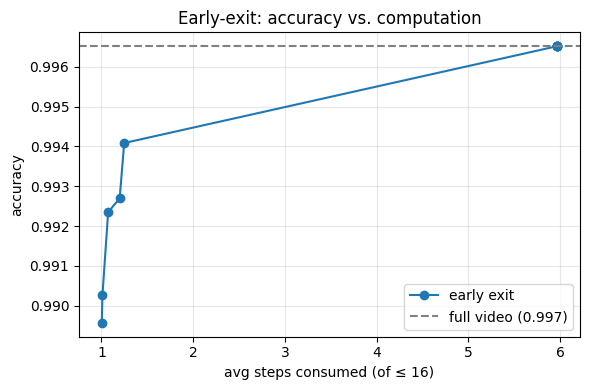

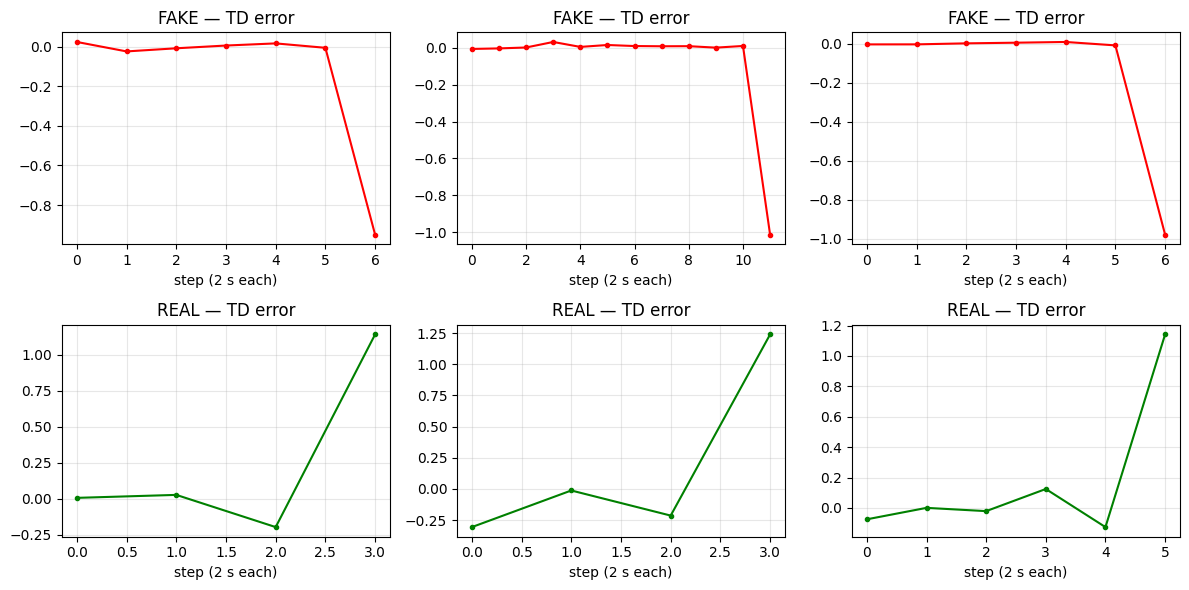


✓ results → tdverdict_results.json | model → best_tdverdict.pth


In [16]:
# ============================================================
# MAIN
# ============================================================
def main():
    print("Loading CLIP...")
    clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
    clip_model = clip_model.float()

    print("\nPreparing splits...")
    train_data, val_data, test_data = prepare_data_splits(CFG.DATASET_ROOT)

    loaders = {}
    for name, data, shuf in [("train", train_data, True),
                             ("val", val_data, False),
                             ("test", test_data, False)]:
        ds = TDPolyGlotFakeDataset(data, clip_preprocess)
        loaders[name] = DataLoader(ds, batch_size=CFG.BATCH_SIZE, shuffle=shuf,
                                   num_workers=CFG.NUM_WORKERS, collate_fn=collate_fn,
                                   pin_memory=True)

    model = TDVerdict(clip_model).to(device)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable params: {n_train/1e6:.2f} M")

    # ---- Stage 1: coherence ----
    print("\n================ STAGE 1: coherence pretraining ================")
    s1_hist = train_stage1(model, loaders["train"], loaders["val"])

    # ---- Stage 2: TD(λ) value ----
    print("\n================ STAGE 2: TD(λ) value training =================")
    s2_hist, best_epoch, best_val = train_stage2(model, loaders["train"], loaders["val"])

    # ---- Test ----
    print(f"\nLoading best model (epoch {best_epoch})...")
    model.load_state_dict(torch.load("best_tdverdict.pth")["model_state_dict"])
    res = evaluate(model, loaders["test"], collect_trajectories=True)

    print("=" * 60)
    print(f"TEST  acc {res['accuracy']:.4f} | prec {res['precision']:.4f} | "
          f"rec {res['recall']:.4f} | f1 {res['f1']:.4f} | auc {res['auc']:.4f}")
    print("=" * 60)
    cm = confusion_matrix(res["labels"], res["preds"])
    print(f"\nConfusion matrix:\n{cm}")
    print(classification_report(res["labels"], res["preds"],
                                target_names=["Real", "Fake"], zero_division=0))

    # ---- The tables that make the paper ----
    print("\nEarly-exit sweep:")
    rows = early_exit_sweep(res["trajectories"])
    for r in rows:
        print(f"  τ={r['tau']:.2f}  acc={r['accuracy']:.4f}  "
              f"avg_steps={r['avg_steps']:.2f}  ({r['avg_video_pct']:.1f}% of video)")
    plot_early_exit(rows, res["accuracy"])
    plot_localization(res["trajectories"])

    json.dump({"config": {k: v for k, v in vars(CFG).items() if not k.startswith("_")},
               "best_epoch": best_epoch, "best_val_acc": best_val,
               "test": {k: float(v) for k, v in res.items()
                        if isinstance(v, (int, float, np.floating))},
               "confusion_matrix": cm.tolist(),
               "early_exit": rows,
               "stage1_history": s1_hist, "stage2_history": s2_hist},
              open("tdverdict_results.json", "w"), indent=2)
    print("\n✓ results → tdverdict_results.json | model → best_tdverdict.pth")
    return model, loaders, (train_data, val_data, test_data), clip_preprocess


model, loaders, splits, clip_preprocess = main()

## Visualization prerequisites (run this before the qualitative cells)

Ensures `clip_model`, `clip_preprocess`, `device`, and `splits` all exist. If you
ran the full training cell above, it just verifies them; if not (or if you only
want the figures), it reconstructs them **without retraining** by loading CLIP and
rebuilding the data splits. This fixes the `splits is not defined` error, which
happens when the qualitative cells are run before `main()` has populated globals.


In [17]:
# ============================================================
# GUARD — make sure the globals the visualization needs exist
# Safe to run whether or not training (main()) has been executed.
# ============================================================
# device (defined in the config cell, but re-assert to be safe)
try:
    device
except NameError:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# CLIP encoder + preprocess (main() keeps these local, so they may be missing)
if "clip_model" not in globals() or "clip_preprocess" not in globals():
    print("Loading CLIP ViT-B/32 (no retraining)...")
    clip_model, clip_preprocess = clip.load("ViT-B/32", device=device)
    clip_model = clip_model.float()
else:
    print("clip_model / clip_preprocess: OK")

# data splits (train, val, test) — rebuild from disk if main() wasn't run
if "splits" not in globals():
    print("Rebuilding data splits from CFG.DATASET_ROOT (no retraining)...")
    _tr, _va, _te = prepare_data_splits(CFG.DATASET_ROOT)
    splits = (_tr, _va, _te)
else:
    print("splits: OK")

# quick sanity report
_n_real = sum(1 for (_p, _m, y) in splits[2] if y == 0)
_n_fake = sum(1 for (_p, _m, y) in splits[2] if y == 1)
print(f"test split: {_n_real} real / {_n_fake} fake  |  device: {device}")
assert _n_real >= 1 and _n_fake >= 1, "Need at least one real and one fake sample in the test split."
print("Prerequisites satisfied \u2713")

Loading CLIP ViT-B/32 (no retraining)...
splits: OK
test split: 153 real / 2722 fake  |  device: cuda
Prerequisites satisfied ✓


In [18]:
# ============================================================
# VISUALIZATION CONFIG
# ============================================================
import os, numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import FancyBboxPatch
from PIL import Image

THEME       = "light"          # "light" (paper) or "dark" (reference banner)
N_PER_CLASS = 3                # samples per class
OUT_DIR     = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
SEED_PICK   = 0                # offset into each class list for reproducibility

# ---- palette ----
if THEME == "dark":
    BG, PANEL, FG, MUTE = "#0B1020", "#161C2E", "#F1F5F9", "#94A3B8"
    REAL_BANNER, FAKE_BANNER = "#0F766E", "#EA7317"
    MEL_CMAP = "magma"
else:
    BG, PANEL, FG, MUTE = "#FFFFFF", "#F1F5F9", "#0F172A", "#64748B"
    REAL_BANNER, FAKE_BANNER = "#047857", "#B45309"
    MEL_CMAP = "magma"
REAL_EDGE, FAKE_EDGE = "#047857", "#EA7317"

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "font.family": "DejaVu Sans",
    "font.size": 11, "text.color": FG, "axes.edgecolor": FG,
})
print(f"Theme={THEME}  samples/class={N_PER_CLASS}  out={OUT_DIR}")

Theme=light  samples/class=3  out=/kaggle/working


In [19]:
# ============================================================
# CLIP ViT-B/32 attention rollout  (Abnar & Zuidema, 2020)
# The visual branch is a frozen ViT — rollout over patch-token attention is the
# faithful saliency for this architecture (no conv maps to Grad-CAM).
# ============================================================
def clip_attention_rollout(clip_model, image_tensor, device, discard_ratio=0.9):
    visual = clip_model.visual
    attn_maps = []
    patched = []
    for blk in visual.transformer.resblocks:
        mha = blk.attn
        orig = mha.forward
        patched.append((mha, orig))
        def make(orig):
            def fwd(query, key, value, need_weights=True, attn_mask=None, **kw):
                out, w = orig(query, key, value, need_weights=True,
                              average_attn_weights=True, attn_mask=attn_mask)
                attn_maps.append(w.detach())
                return out, w
            return fwd
        mha.forward = make(orig)
    try:
        with torch.no_grad():
            _ = clip_model.encode_image(image_tensor.unsqueeze(0).to(device))
    finally:
        for mha, orig in patched:
            mha.forward = orig
    if not attn_maps:
        raise RuntimeError("No attention captured; CLIP internals differ.")
    N = attn_maps[0].shape[-1]
    result = torch.eye(N, device=attn_maps[0].device)
    for a in attn_maps:
        a = a[0] + torch.eye(N, device=attn_maps[0].device)
        a = a / a.sum(-1, keepdim=True)
        if discard_ratio > 0:
            flat = a.view(-1)
            k = int(flat.numel() * discard_ratio)
            if k > 0:
                thr = flat.kthvalue(k).values
                a = torch.where(a < thr, torch.zeros_like(a), a)
                a = a / a.sum(-1, keepdim=True).clamp(min=1e-8)
        result = a @ result
    mask = result[0, 1:]
    side = int(mask.numel() ** 0.5)
    mask = mask.reshape(side, side).cpu().numpy()
    return (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)


def blend_heatmap(pil_224, sal, alpha=0.55):
    """Return an RGB uint8 array: face with jet heatmap overlaid."""
    import matplotlib.cm as cm
    base = np.asarray(pil_224.convert("RGB")).astype(float) / 255.0
    heat = np.asarray(Image.fromarray((sal * 255).astype(np.uint8))
                      .resize((224, 224), Image.BICUBIC)) / 255.0
    jet = cm.get_cmap("jet")(heat)[..., :3]
    out = (1 - alpha) * base + alpha * jet
    return (np.clip(out, 0, 1) * 255).astype(np.uint8)

In [20]:
# ============================================================
# Sample loading helpers (on-disk frames + stored mel PNG)
# ============================================================
def list_frames(frames_folder):
    return sorted(os.path.join(frames_folder, f)
                  for f in os.listdir(frames_folder) if f.endswith(".png"))

def representative_face(frames_folder):
    """A clear mid-sequence frame, resized to 224x224."""
    files = list_frames(frames_folder)
    if not files:
        raise FileNotFoundError(frames_folder)
    fn = files[len(files) // 2]
    return Image.open(fn).convert("RGB").resize((224, 224))

def sibling_mel_path(frames_folder):
    audio = os.path.join(os.path.dirname(frames_folder), "Audio")
    mels = [f for f in os.listdir(audio)
            if "spectrogram" in f.lower() and f.endswith(".png")]
    return os.path.join(audio, mels[0])

def load_full_mel(frames_folder):
    return np.asarray(Image.open(sibling_mel_path(frames_folder)).convert("L")) / 255.0

def pick_class_samples(splits, label, n, offset=0):
    test = splits[2]
    paths = [p for (p, _m, y) in test if y == label]
    if len(paths) < n + offset:
        for s in splits[:2]:
            paths += [p for (p, _m, y) in s if y == label]
    return paths[offset: offset + n]

In [21]:
# ============================================================
# One combined image per sample:  Face | Attention Heatmap | Mel Spectrogram
# ============================================================
def render_one_sample(frames_folder, class_name, banner_color, edge_color,
                      clip_model, clip_preprocess, device, out_path):
    ff = os.path.normpath(frames_folder)
    vid_dir = os.path.dirname(ff) if os.path.basename(ff).lower() == "frames" else ff
    vid_id = os.path.basename(vid_dir)
    parent = os.path.basename(os.path.dirname(vid_dir))

    pil = representative_face(frames_folder)
    sal = clip_attention_rollout(clip_model, clip_preprocess(pil), device)
    heat = blend_heatmap(pil, sal)
    mel = load_full_mel(frames_folder)

    fig = plt.figure(figsize=(12, 3.6), facecolor=BG)
    outer = gridspec.GridSpec(2, 1, height_ratios=[0.15, 1.0], hspace=0.34)

    # banner
    axb = fig.add_subplot(outer[0]); axb.axis("off")
    axb.add_patch(FancyBboxPatch((0, 0), 1, 1, transform=axb.transAxes,
                  boxstyle="round,pad=0.02,rounding_size=0.04",
                  facecolor=banner_color, edgecolor="none"))
    axb.text(0.012, 0.5, f"{class_name}   \u00b7   {parent}   \u00b7   {vid_id}",
             transform=axb.transAxes, ha="left", va="center",
             fontsize=13, fontweight="bold", color="white")

    # content: 3 panels
    inner = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[1],
                                             wspace=0.12, width_ratios=[1, 1, 1.9])
    # face
    ax0 = fig.add_subplot(inner[0]); ax0.imshow(pil)
    ax0.set_title("Input frame", fontsize=11, fontweight="bold", color=FG, pad=5)
    ax0.set_xticks([]); ax0.set_yticks([])
    for s in ax0.spines.values(): s.set_color(edge_color); s.set_linewidth(2.4)
    # heatmap
    ax1 = fig.add_subplot(inner[1]); ax1.imshow(heat)
    ax1.set_title("CLIP attention", fontsize=11, fontweight="bold", color=FG, pad=5)
    ax1.set_xticks([]); ax1.set_yticks([])
    for s in ax1.spines.values(): s.set_color(edge_color); s.set_linewidth(2.4)
    # mel
    ax2 = fig.add_subplot(inner[2])
    im = ax2.imshow(mel, aspect="auto", origin="lower", cmap=MEL_CMAP)
    ax2.set_title("Log-Mel spectrogram", fontsize=11, fontweight="bold", color=FG, pad=5)
    ax2.set_xlabel("Time frame", fontsize=9); ax2.set_ylabel("Mel bin", fontsize=9)
    ax2.tick_params(labelsize=8)
    for s in ax2.spines.values(): s.set_color("#334155"); s.set_linewidth(1.4)
    fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.03)

    fig.savefig(out_path + ".png", bbox_inches="tight", facecolor=BG)
    fig.savefig(out_path + ".pdf", bbox_inches="tight", facecolor=BG)
    plt.close(fig)
    print("saved", out_path + ".png / .pdf")

In [22]:
# ============================================================
# DRIVER — 3 Real + 3 Fake, each saved as its OWN image
# ============================================================
real_dirs = pick_class_samples(splits, label=0, n=N_PER_CLASS, offset=SEED_PICK)
fake_dirs = pick_class_samples(splits, label=1, n=N_PER_CLASS, offset=SEED_PICK)
assert real_dirs, "No real samples found — check CFG.DATASET_ROOT / splits."
assert fake_dirs, "No fake samples found — check CFG.DATASET_ROOT / splits."
print("Real:", *real_dirs, sep="\n  ")
print("Fake:", *fake_dirs, sep="\n  ")

for i, fd in enumerate(real_dirs, 1):
    render_one_sample(fd, "RealVideo-RealAudio", REAL_BANNER, REAL_EDGE,
                      clip_model, clip_preprocess, device,
                      os.path.join(OUT_DIR, f"qual_real_{i}"))

for i, fd in enumerate(fake_dirs, 1):
    render_one_sample(fd, "FakeVideo (manipulated)", FAKE_BANNER, FAKE_EDGE,
                      clip_model, clip_preprocess, device,
                      os.path.join(OUT_DIR, f"qual_fake_{i}"))

print("\nDone — 6 separate figures in", OUT_DIR)

Real:
  /kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2/Real/ru_111/Frames
  /kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2/Real/ru_76/Frames
  /kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2/Real/en_83/Frames
Fake:
  /kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2/Fake/fr_4_to_en_MicroTts/Frames
  /kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2/Fake/fr_98_to_ru_Xtts/Frames
  /kaggle/input/datasets/sajjad006/polyglotfakev2/processed_datasetv2/Fake/fr_101_to_ja_Bark/Frames


/tmp/ipykernel_22/1684358037.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")(heat)[..., :3]


saved /kaggle/working/qual_real_1.png / .pdf


/tmp/ipykernel_22/1684358037.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")(heat)[..., :3]


saved /kaggle/working/qual_real_2.png / .pdf


/tmp/ipykernel_22/1684358037.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")(heat)[..., :3]


... (3 outputs left out)

/tmp/ipykernel_22/1684358037.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")(heat)[..., :3]


saved /kaggle/working/qual_fake_2.png / .pdf


/tmp/ipykernel_22/1684358037.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")(heat)[..., :3]


saved /kaggle/working/qual_fake_3.png / .pdf

Done — 6 separate figures in /kaggle/working


In [23]:
# Optional: k-shot value-head adaptation
few_shot_adapt(model, splits[0], loaders["test"], clip_preprocess, k=5)

[few-shot k=5]  acc 0.8369  f1 0.9100  auc 0.5920


{'accuracy': 0.8368695652173913,
 'precision': 0.9522280208751506,
 'recall': 0.8714180749448934,
 'f1': 0.9100326107807405,
 'auc': np.float64(0.5919834992532403),
 'preds': array([1, 1, 1, ..., 0, 1, 1]),
 'labels': array([1, 1, 1, ..., 1, 1, 1]),
 'probs': array([0.5412638 , 0.5251234 , 0.5471868 , ..., 0.48202267, 0.5107038 ,
        0.5397331 ], dtype=float32)}

In [24]:
few_shot_adapt(model, splits[0], loaders["test"], clip_preprocess, k=4)

[few-shot k=4]  acc 0.5649  f1 0.7123  auc 0.5461


{'accuracy': 0.5648695652173913,
 'precision': 0.9520590043023971,
 'recall': 0.5690668626010287,
 'f1': 0.7123476661301449,
 'auc': np.float64(0.5460733889441155),
 'preds': array([0, 0, 0, ..., 0, 0, 1]),
 'labels': array([1, 1, 1, ..., 1, 1, 1]),
 'probs': array([0.45766813, 0.49222288, 0.48949048, ..., 0.40164423, 0.47052774,
        0.5298801 ], dtype=float32)}

In [25]:
res=few_shot_adapt(model, splits[0], loaders["test"], clip_preprocess, k=3)

[few-shot k=3]  acc 0.7597  f1 0.8610  auc 0.5391


In [26]:
few_shot_adapt(model, splits[0], loaders["test"], clip_preprocess, k=2)

[few-shot k=2]  acc 0.8970  f1 0.9455  auc 0.5127


{'accuracy': 0.8970434782608696,
 'precision': 0.9476014760147602,
 'recall': 0.9434239529757531,
 'f1': 0.9455081001472754,
 'auc': np.float64(0.5126781057757416),
 'preds': array([1, 1, 1, ..., 1, 1, 1]),
 'labels': array([1, 1, 1, ..., 1, 1, 1]),
 'probs': array([0.52837384, 0.5462854 , 0.5192333 , ..., 0.54801536, 0.5152195 ,
        0.5661421 ], dtype=float32)}

In [27]:
few_shot_adapt(model, splits[0], loaders["test"], clip_preprocess, k=1)

[few-shot k=1]  acc 0.5005  f1 0.6578  auc 0.4344


{'accuracy': 0.5005217391304347,
 'precision': 0.9362279511533242,
 'recall': 0.5069801616458487,
 'f1': 0.657769304099142,
 'auc': np.float64(0.43440761070531564),
 'preds': array([1, 0, 0, ..., 1, 0, 1]),
 'labels': array([1, 1, 1, ..., 1, 1, 1]),
 'probs': array([0.58061266, 0.48828948, 0.40577227, ..., 0.53203624, 0.39262614,
        0.5217705 ], dtype=float32)}